# Calories Burnt — Regression (Synthetic Dataset)

The Kaggle "calories burnt prediction" dataset I originally wanted requires auth, so I built a small synthetic version (500 rows) with plausible relationships between age, gender, exercise duration, heart rate, body temperature, and calories burned. The synthetic data uses a formula loosely based on Keytel et al. (2005) for the heart-rate term, plus a duration coefficient and some noise.

Obviously the model will fit this dataset really well because I generated it from a known function. The interesting question is which features it picks up and how much noise it tolerates.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(123)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/calories_burnt"); DATA_DIR.mkdir(parents=True, exist_ok=True)


## generate the synthetic data

In [2]:
# Roughly: calories ≈ duration * (a + b*HR + c*age + d*sex) with multiplicative noise.
# Constants are picked so the output sits in a believable 20-400 cal range.
N = 500
rng = np.random.default_rng(123)
age = rng.integers(18, 65, size=N)
sex = rng.integers(0, 2, size=N)  # 0=female, 1=male
duration = rng.uniform(5, 60, size=N)             # minutes
heart_rate = rng.normal(120, 18, size=N).clip(70, 200)
body_temp = rng.normal(38.5, 0.6, size=N).clip(36.5, 41.0)

# Keytel-ish: HR is the dominant term, sex shifts intercept, age has a small effect.
base = duration * (
    0.18 * heart_rate
    + 0.05 * age * (1 - 0.4 * sex)   # men: weaker age penalty
    + 4.0 * sex
    - 8.0
)
# small body-temp coupling (overheated → slightly more reported burn)
base += duration * 1.8 * (body_temp - 37.0)

noise = rng.normal(0, 8, size=N)
calories = (base + noise).clip(min=10)

df = pd.DataFrame({
    "age": age, "sex": sex, "duration_min": duration.round(2),
    "heart_rate": heart_rate.round(1), "body_temp_c": body_temp.round(2),
    "calories": calories.round(1),
})
df.to_csv(DATA_DIR / "calories_synth.csv", index=False)
print(df.shape)
df.head()


(500, 6)


,age,sex,duration_min,heart_rate,body_temp_c,calories
0,18,1,53.41,99.7,38.61,921.6
1,50,1,8.14,108.4,39.11,168.2
2,45,1,49.07,141.5,38.51,1250.6
3,20,1,52.83,142.2,38.43,1300.9
4,60,1,18.47,111.3,38.09,366.3


## quick look

/var/folders/6_/qqrf82qn33v6prn9sqhbl1k40000gn/T/ipykernel_13656/1291311251.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(["female", "male"])


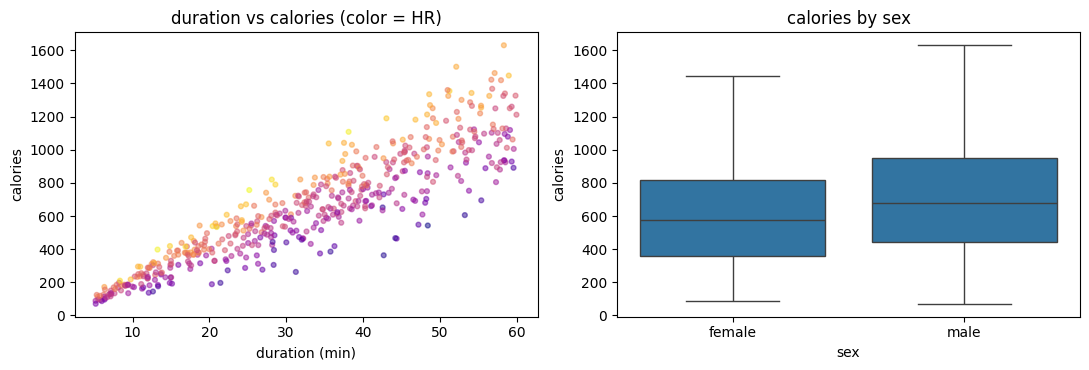

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(df["duration_min"], df["calories"], s=12, alpha=0.5, c=df["heart_rate"], cmap="plasma")
ax[0].set_xlabel("duration (min)"); ax[0].set_ylabel("calories")
ax[0].set_title("duration vs calories (color = HR)")
sns.boxplot(data=df, x="sex", y="calories", ax=ax[1])
ax[1].set_xticklabels(["female", "male"])
ax[1].set_title("calories by sex")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()


## models

In [4]:
features = ["age", "sex", "duration_min", "heart_rate", "body_temp_c"]
X = df[features].values
y = df["calories"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

rows = []
for name, m in [
    ("LinReg", LinearRegression()),
    ("RF",     RandomForestRegressor(n_estimators=200, random_state=123)),
    ("GBR",    GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=123)),
]:
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    r2 = float(r2_score(y_test, pred))
    mae = float(mean_absolute_error(y_test, pred))
    rows.append({"model": name, "rmse": round(rmse, 2), "mae": round(mae, 2), "r2": round(r2, 4)})
pd.DataFrame(rows).set_index("model")


,rmse,mae,r2
model,,,
LinReg,66.21,48.41,0.9605
RF,61.09,45.47,0.9664
GBR,40.84,29.37,0.9850


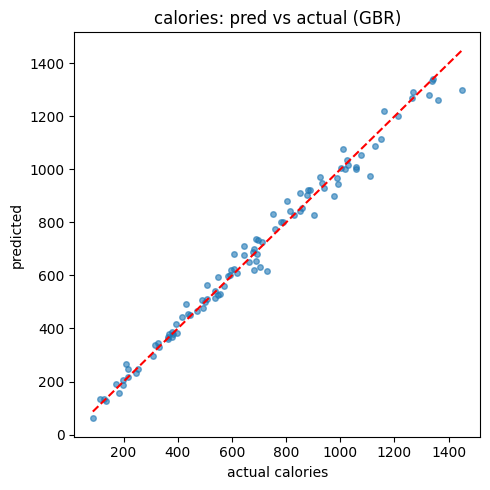

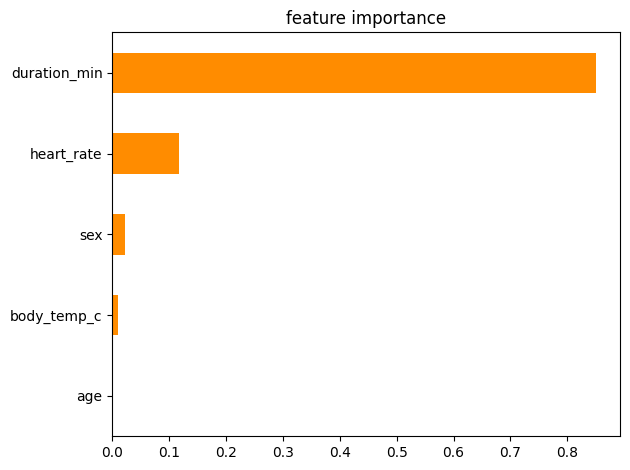

In [5]:
# pred-vs-actual using whatever's most informative — GBR usually
gbr = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=123)
gbr.fit(X_train, y_train)
pred = gbr.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=16, alpha=0.6)
lo, hi = y_test.min(), y_test.max()
plt.plot([lo, hi], [lo, hi], "r--")
plt.xlabel("actual calories"); plt.ylabel("predicted")
plt.title("calories: pred vs actual (GBR)")
plt.tight_layout(); plt.savefig(ART / "pred_vs_actual.png", dpi=120); plt.show()

fi = pd.Series(gbr.feature_importances_, index=features).sort_values()
fi.plot(kind="barh", color="darkorange")
plt.title("feature importance"); plt.tight_layout()
plt.savefig(ART / "fi.png", dpi=120); plt.show()


## caveats

This is synthetic. The R^2 is going to look unreasonably good because the only thing keeping the model from a perfect fit is the Gaussian noise I added at the end. The point of the notebook is the pipeline shape, not the numbers — if I had access to the real Kaggle dataset I'd swap the data load and re-run with no other changes.

Duration and heart rate dominate the importance ranking, which lines up with how I generated the data (multiplicative interaction). Age and sex sneak in at the bottom. Body temp is barely above noise — the coefficient I gave it was small.
